# 09_08 Variational Autoencoders: the ELBO, the Reparameterisation Trick and the Latent Space

**Learning objectives**
- Derive the **evidence lower bound (ELBO)** $\ln p(x)\ge E_{q(z|x)}[\ln p(x|z)]-\mathrm{KL}(q(z|x)\|p(z))$ and show that the gap is exactly $\mathrm{KL}(q(z|x)\|p(z|x))$.
- Use the **closed-form Gaussian KL** (08_02) and the **reparameterisation trick** $z=\mu+\sigma\odot\varepsilon$, and compare its gradient with the score-function estimator.
- Train a VAE from scratch in NumPy (encoder, decoder, manual backward pass) on a 3D manifold, look at the **latent space**, sample **new data** from the prior and interpolate.
- Understand the **$\beta$-VAE trade-off** (reconstruction against KL), **active latent dimensions** and **posterior collapse**.

**Prerequisites:** [08_02 KL divergence](../../module_08_information/notebooks/08_02_kl_js_divergence.ipynb), [09_04 Density estimation and EM](09_04_density_estimation_kde_gmm_em.ipynb), [09_06 Randomness inside neural networks](09_06_neural_net_randomness.ipynb), [09_07 LLM sampling](09_07_llm_sampling.ipynb) (Gumbel-softmax and reparameterisation), [07_03 MCMC](../../module_07_bayesian/notebooks/07_03_mcmc_metropolis.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
For two Gaussians the KL divergence is available in closed form (08_02): for $q=N(\mu,\mathrm{diag}\,\sigma^2)$ and $p=N(0,I)$, $\mathrm{KL}(q\|p)=\frac12\sum_j(\mu_j^2+\sigma_j^2-1-\ln\sigma_j^2)$. EM (09_04) alternates a soft guess of hidden variables with a parameter update by maximising a lower bound on $\ln p(x)$; a VAE keeps that bound but makes both parts neural networks. A sample can be written as a deterministic function of parameters and parameter-free noise (09_07): $z=\mu+\sigma\varepsilon$, $\varepsilon\sim N(0,1)$.

## 3. Intuition and story
Imagine a high-dimensional object (a 3D point) that is really described by just two hidden numbers: where it sits on a rolled-up sheet. A **variational autoencoder** learns that hidden description without being told. An **encoder** looks at a data point $x$ and says "the hidden code $z$ is probably around $\mu(x)$, with uncertainty $\sigma(x)$"; a **decoder** takes a code and produces a data point. Training asks for two things at once: the decoder should be able to rebuild $x$ from the code (reconstruction), and the codes of all data should look like draws from a simple known distribution, the standard normal (the KL term). The second requirement is what turns an autoencoder into a **generative model**: once codes are spread like $N(0,I)$ we can draw a new code from it, decode it and obtain a new, realistic data point.

## 4. Formal definitions

**Generative model:** $z\sim N(0,I_d)$, $x\mid z\sim N(f_\theta(z),\sigma_x^2I)$ (decoder $f_\theta$). **Approximate posterior (encoder):** $q_\phi(z\mid x)=N(\mu_\phi(x),\mathrm{diag}\,\sigma_\phi^2(x))$.

| Quantity | Formula |
|---|---|
| **ELBO** | $\mathcal L(x)=E_{q_\phi(z|x)}[\ln p_\theta(x|z)]-\mathrm{KL}\big(q_\phi(z|x)\|p(z)\big)$ |
| **Identity** | $\ln p_\theta(x)=\mathcal L(x)+\mathrm{KL}\big(q_\phi(z|x)\|p_\theta(z|x)\big)\ \ge\ \mathcal L(x)$ |
| **Gaussian KL term** | $\tfrac12\sum_j(\mu_j^2+\sigma_j^2-1-\ln\sigma_j^2)$ |
| **Reconstruction term** (Gaussian decoder) | $-\dfrac1{2\sigma_x^2}\|x-f_\theta(z)\|^2-\dfrac D2\ln(2\pi\sigma_x^2)$ |
| **Reparameterisation** | $z=\mu_\phi(x)+\sigma_\phi(x)\odot\varepsilon$, $\varepsilon\sim N(0,I)$ |
| **$\beta$-VAE** | maximise $E[\ln p(x|z)]-\beta\,\mathrm{KL}$ |
| **Active unit** | latent dimension $j$ with $\overline{\mathrm{KL}_j}>0.05$ nats (the posterior differs from the prior) |

## 5. Derivations

### 5.1 The ELBO and its gap
For any density $q(z)$, $\ \ln p(x)=\ln\int p(x,z)dz=E_q\ln\dfrac{p(x,z)}{q(z)}+E_q\ln\dfrac{q(z)}{p(z|x)}=\mathcal L+\mathrm{KL}(q\|p(\cdot|x))$. The second term is non-negative, so $\ln p(x)\ge\mathcal L$, with equality iff $q=p(z|x)$. Writing $p(x,z)=p(x|z)p(z)$ gives $\mathcal L=E_q\ln p(x|z)-\mathrm{KL}(q\|p(z))$. **In plain words.** The ELBO is a lower bound on how likely the data are; the shortfall is exactly how far the encoder's guess is from the true posterior over codes, so a better encoder tightens the bound.

### 5.2 Why the KL has a closed form, and what it does
With $q=N(\mu,\sigma^2)$ and $p=N(0,1)$ the formula of 08_02 gives $\frac12(\mu^2+\sigma^2-1-\ln\sigma^2)$: zero at $\mu=0,\sigma=1$, growing as the code moves away from the origin or becomes too certain ($\sigma\to0$). **In plain words.** The KL term is a price for placing a data point's code far from the centre or pinning it down too sharply; it pushes all codes to fill the standard normal ball.

### 5.3 The reparameterisation trick
The gradient of $E_{z\sim q_\phi}[f(z)]$ with respect to $\phi$ cannot pass through the sampling. Writing $z=\mu+\sigma\varepsilon$ makes the expectation over a fixed distribution of $\varepsilon$: $\nabla_\phi E_\varepsilon[f(\mu_\phi+\sigma_\phi\varepsilon)]=E_\varepsilon[\nabla_\phi f(\cdot)]$, so ordinary backpropagation works. The alternative **score-function** estimator $E[f(z)\nabla_\phi\ln q_\phi(z)]$ is unbiased too but has a much larger variance. **In plain words.** Move the randomness out of the way: sample parameter-free noise first, then compute $z$ with a differentiable formula; gradients then flow through $\mu$ and $\sigma$.

### 5.4 The $\beta$ trade-off
With $\beta>1$ the model is forced to use the latent code more frugally: codes are closer to the prior (smoother, better for sampling) but reconstructions are blurrier; with $\beta\to0$ the model is a plain autoencoder with excellent reconstructions and a latent space with holes. **In plain words.** $\beta$ sets how much a bit of latent information must pay for itself.

### 5.5 Active units and posterior collapse
For a latent dimension that the decoder ignores, the optimum is $q(z_j|x)=p(z_j)$ for every $x$ (KL $=0$): the dimension is "collapsed". With a latent size larger than the data's intrinsic dimension, the VAE switches the extra dimensions off by itself. **In plain words.** The KL term charges for every dimension; an unused one costs nothing only if its posterior equals the prior, so extra dimensions collapse and the number of active dimensions estimates the intrinsic dimension of the data.

## 6. Properties and relationships
- **EM as a special case:** if the bound is made tight by setting $q=p(z|x)$ (E-step) and then maximised in $\theta$ (M-step) we have EM (09_04); the VAE replaces both steps by amortised neural networks and stochastic gradients.
- **Amortisation gap:** one encoder network for all $x$ cannot be exactly the true posterior of each $x$; the ELBO is looser than with per-datapoint optimisation.
- **Fixed decoder variance** $\sigma_x^2$ controls the balance of the two terms; learning it makes the model less blurry.
- **Posterior collapse** is common with powerful decoders (text, images with autoregressive decoders).
- **Generation:** sample $z\sim N(0,I)$, decode; **interpolation** between two codes gives smooth transitions if the latent space has no holes.
- **Link to ML and AI:** image and speech generation, **latent diffusion models** (a VAE compresses images to a latent space where diffusion, 09_09, runs), VQ-VAEs (categorical latents with Gumbel-softmax, 09_07), representation learning and anomaly detection by reconstruction error (09_05), molecule design.

## 7. A VAE from scratch

Two small tanh networks with a manual backward pass: the encoder maps $x$ to $(\mu,\ln\sigma^2)$; the decoder maps $z$ back to $x$. The backward pass routes the reconstruction gradient through the sampled $z$ (reparameterisation) and adds the analytic KL gradient. A finite-difference check validates it.

In [2]:
class Net:
    def __init__(self, sizes, seed=0):
        g = np.random.default_rng(seed); self.W = [g.normal(0, np.sqrt(2 / (i + o)), (i, o)) for i, o in zip(sizes[:-1], sizes[1:])]; self.b = [np.zeros(o) for o in sizes[1:]]; self.m = [np.zeros_like(p) for p in self.W + self.b]; self.v = [np.zeros_like(p) for p in self.W + self.b]; self.t = 0
    def forward(self, X):
        h = X; self.inp = []; self.th = []
        for l in range(len(self.W)):
            self.inp.append(h); a = h @ self.W[l] + self.b[l]
            if l == len(self.W) - 1: return a
            h = np.tanh(a); self.th.append(h)
    def backward(self, dout):
        L = len(self.W); gW = [None] * L; gb = [None] * L; d = dout
        for l in reversed(range(L)):
            gW[l] = self.inp[l].T @ d; gb[l] = d.sum(axis=0); d_in = d @ self.W[l].T
            if l > 0: d = d_in * (1 - self.th[l - 1] ** 2)
        self.dinput = d_in; return gW + gb
    def adam(self, grads, lr=2e-3, b1=0.9, b2=0.999):
        self.t += 1
        for k, (p, gk) in enumerate(zip(self.W + self.b, grads)): self.m[k] = b1 * self.m[k] + (1 - b1) * gk; self.v[k] = b2 * self.v[k] + (1 - b2) * gk ** 2; p -= lr * (self.m[k] / (1 - b1 ** self.t)) / (np.sqrt(self.v[k] / (1 - b2 ** self.t)) + 1e-8)
class VAE:
    def __init__(self, d, zdim=2, hidden=64, sigma=0.15, beta=1.0, seed=0): self.enc = Net([d, hidden, hidden, 2 * zdim], seed); self.dec = Net([zdim, hidden, hidden, d], seed + 1); self.zdim = zdim; self.sigma = sigma; self.beta = beta
    def encode(self, X): o = self.enc.forward(X); return o[:, :self.zdim], np.clip(o[:, self.zdim:], -9, 4)
    def losses(self, X, rng=None, eps=None):
        mu, lv = self.encode(X); eps = rng.normal(size=mu.shape) if eps is None else eps; z = mu + np.exp(0.5 * lv) * eps; xh = self.dec.forward(z); n = len(X)
        rec = 0.5 * np.sum((X - xh) ** 2) / (self.sigma ** 2 * n); kl_dim = 0.5 * np.mean(mu ** 2 + np.exp(lv) - 1 - lv, axis=0); return rec, kl_dim, (mu, lv, eps, z, xh)
    def step(self, X, rng, lr=2e-3):
        rec, kl_dim, (mu, lv, eps, z, xh) = self.losses(X, rng); n = len(X); gdec = self.dec.backward((xh - X) / (self.sigma ** 2 * n)); dz = self.dec.dinput
        dmu = dz + self.beta * mu / n; dlv = dz * eps * 0.5 * np.exp(0.5 * lv) + self.beta * 0.5 * (np.exp(lv) - 1) / n
        genc = self.enc.backward(np.hstack([dmu, dlv])); self.dec.adam(gdec, lr); self.enc.adam(genc, lr); return rec, kl_dim
def fit(vae, X, epochs=2000, seed=0, lr=2e-3, hist=False):
    rng = np.random.default_rng(seed); h = []
    for ep in range(epochs):
        rec, kl_dim = vae.step(X, rng, lr)
        if hist and ep % 50 == 0: h.append((ep, rec, kl_dim.sum()))
    return h
# gradient check of the whole VAE loss (fixed noise)
g = np.random.default_rng(1); Xg = g.normal(size=(6, 3)); v = VAE(3, 2, hidden=8, sigma=0.5, seed=3); eps0 = g.normal(size=(6, 2))
def total(): rec, kl_dim, _ = v.losses(Xg, eps=eps0); return rec + v.beta * kl_dim.sum()
rec, kl_dim, (mu, lv, eps, z, xh) = v.losses(Xg, eps=eps0); gdec = v.dec.backward((xh - Xg) / (v.sigma ** 2 * 6)); dz = v.dec.dinput; dmu = dz + mu / 6; dlv = dz * eps * 0.5 * np.exp(0.5 * lv) + 0.5 * (np.exp(lv) - 1) / 6; genc = v.enc.backward(np.hstack([dmu, dlv])); worst = 0
for net, gr in [(v.dec, gdec), (v.enc, genc)]:
    for k, p in enumerate(net.W + net.b):
        idx = next(np.ndindex(*p.shape)); old = p[idx]; p[idx] = old + 1e-6; lp = total(); p[idx] = old - 1e-6; lm = total(); p[idx] = old; worst = max(worst, abs((lp - lm) / 2e-6 - gr[k][idx]))
print("largest gradient error (backprop against finite differences):", worst); assert worst < 1e-5

largest gradient error (backprop against finite differences): 4.054156454991187e-10


## 8. 2D visuals

### 8.1 The data: a Swiss roll
1,000 points on a rolled sheet in 3D, $x=(t\cos t,\,h,\,t\sin t)$ with $t\in[1.5\pi,4.5\pi]$ and $h\in[0,10]$, standardised. The sheet has two intrinsic coordinates $(t,h)$ although the points live in 3D. Colour is $t$.

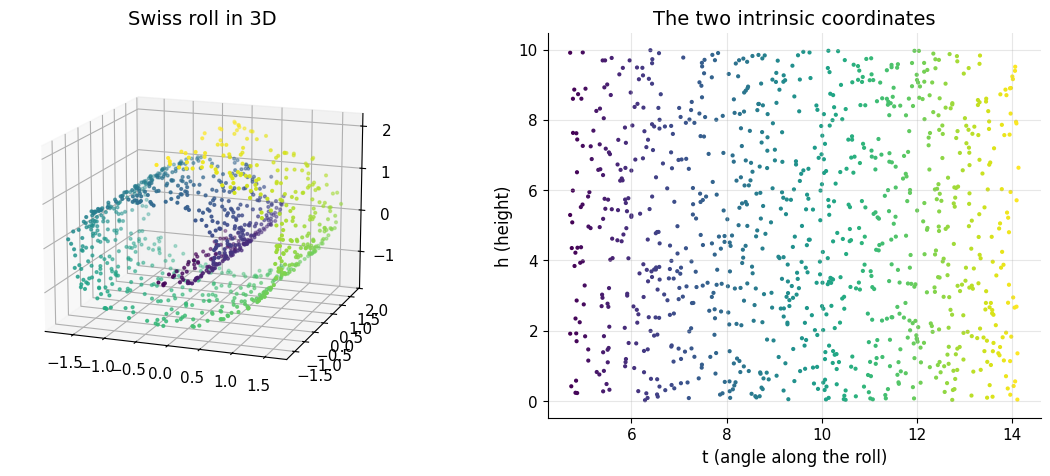

standardised data: mean [ 0. -0. -0.] sd [1. 1. 1.]


In [3]:
g = np.random.default_rng(0); n = 1000; t = g.uniform(1.5 * np.pi, 4.5 * np.pi, n); h = g.uniform(0, 10, n); Xraw = np.column_stack([t * np.cos(t), h, t * np.sin(t)]) + 0.1 * g.normal(size=(n, 3)); mu_x, sd_x = Xraw.mean(axis=0), Xraw.std(axis=0); X = (Xraw - mu_x) / sd_x
fig = plt.figure(figsize=(14, 5)); ax = fig.add_subplot(1, 2, 1, projection="3d"); ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, cmap="viridis", s=4); ax.set_title("Swiss roll in 3D"); ax.view_init(elev=15, azim=-70)
ax = fig.add_subplot(1, 2, 2); ax.scatter(t, h, c=t, cmap="viridis", s=4); ax.set_xlabel("t (angle along the roll)"); ax.set_ylabel("h (height)"); ax.set_title("The two intrinsic coordinates")
plt.show(); print("standardised data: mean", X.mean(axis=0).round(3), "sd", X.std(axis=0).round(3)); assert np.allclose(X.mean(axis=0), 0, atol=1e-9) and np.allclose(X.std(axis=0), 1)

### 8.2 Training the VAE: the two terms of the loss
The reconstruction term and the KL term (sum over the two latent dimensions) during 2,000 full-batch Adam steps.

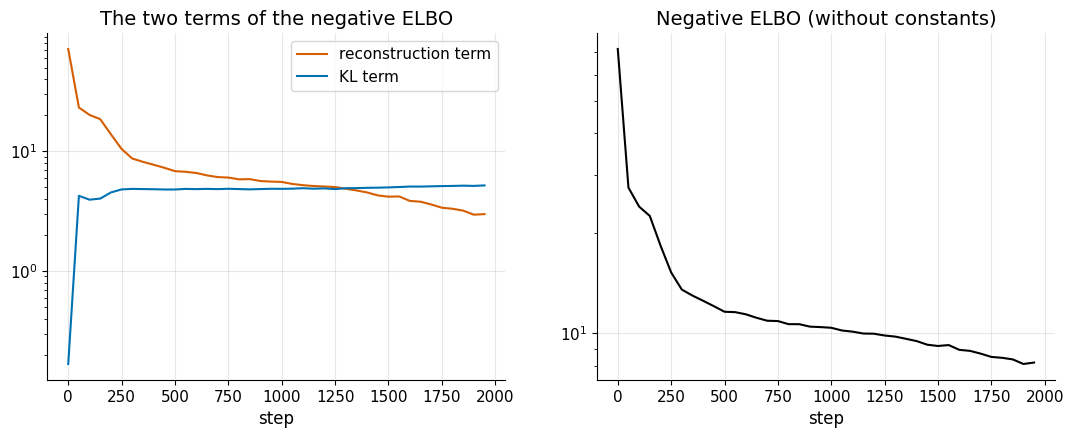

final: reconstruction term 2.90, KL per dimension [2.769 2.383], reconstruction RMSE (standardised units) 0.1660


In [4]:
vae = VAE(3, 2, hidden=64, sigma=0.15, beta=1.0, seed=2); hist = fit(vae, X, epochs=2000, seed=3, hist=True); H = np.array(hist); rng = np.random.default_rng(9); rec_f, kl_f, (mu_f, lv_f, _, z_f, xh_f) = vae.losses(X, rng)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5)); axes[0].plot(H[:, 0], H[:, 1], color=HIGHLIGHT, label="reconstruction term"); axes[0].plot(H[:, 0], H[:, 2], color=MAIN, label="KL term"); axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].legend(); axes[0].set_title("The two terms of the negative ELBO")
axes[1].plot(H[:, 0], H[:, 1] + H[:, 2], color="black"); axes[1].set_yscale("log"); axes[1].set_xlabel("step"); axes[1].set_title("Negative ELBO (without constants)")
plt.show(); rmse = np.sqrt(np.mean((X - vae.dec.forward(mu_f)) ** 2)); print(f"final: reconstruction term {rec_f:.2f}, KL per dimension {kl_f.round(3)}, reconstruction RMSE (standardised units) {rmse:.4f}"); assert H[-1, 1] + H[-1, 2] < H[0, 1] + H[0, 2] and rmse < 0.35

### 8.3 The learned latent space
Left: the posterior means $\mu(x)$ of the 1,000 points, coloured by $t$ and by $h$: the roll has been unrolled into a plane. Right: the decoder applied to a regular grid of latent codes sweeps out the sheet.

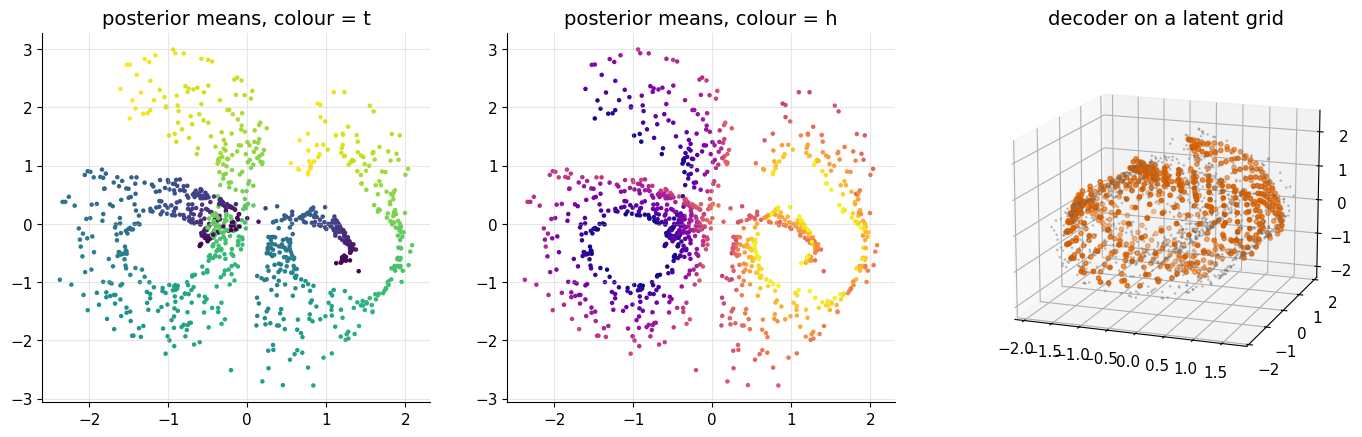

neighbourhood preservation: 0.724 (random embedding: 0.026) | correlation of the latent coordinates with h: [0.799 0.154]


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].scatter(mu_f[:, 0], mu_f[:, 1], c=t, cmap="viridis", s=5); axes[0].set_title("posterior means, colour = t"); axes[1].scatter(mu_f[:, 0], mu_f[:, 1], c=h, cmap="plasma", s=5); axes[1].set_title("posterior means, colour = h")
gz = np.linspace(-2.2, 2.2, 25); GZ = np.array([[a, b] for a in gz for b in gz]); GX = vae.dec.forward(GZ); axes[2].remove(); ax3 = fig.add_subplot(1, 3, 3, projection="3d"); ax3.scatter(X[:, 0], X[:, 1], X[:, 2], s=1, color=NEUTRAL, alpha=0.3); ax3.scatter(GX[:, 0], GX[:, 1], GX[:, 2], s=10, color=HIGHLIGHT); ax3.set_title("decoder on a latent grid"); ax3.view_init(elev=15, azim=-70)
plt.show()
from scipy.spatial import cKDTree
def trust(Z, A, k=10, K=30):
    nz = cKDTree(Z).query(Z, k + 1)[1][:, 1:]; na = cKDTree(A).query(A, K + 1)[1][:, 1:]; return np.mean([len(set(nz[i]) & set(na[i])) / k for i in range(len(Z))])
A_true = np.column_stack([(t - t.mean()) / t.std(), (h - h.mean()) / h.std()]); tr_ = trust(mu_f, A_true); tr_rand = trust(np.random.default_rng(1).normal(size=(n, 2)), A_true); print(f"neighbourhood preservation: {tr_:.3f} (random embedding: {tr_rand:.3f}) | correlation of the latent coordinates with h: {np.abs(np.corrcoef(mu_f.T, h)[2, :2]).round(3)}"); assert tr_ > 0.6 and tr_ > 5 * tr_rand

## 9. 3D visuals

### 9.1 Static: generated samples against the data
New points generated by decoding 2,000 draws from the prior $N(0,I)$ (red) overlaid on the training data (grey): the VAE has learned the manifold, and the draws lie on it.

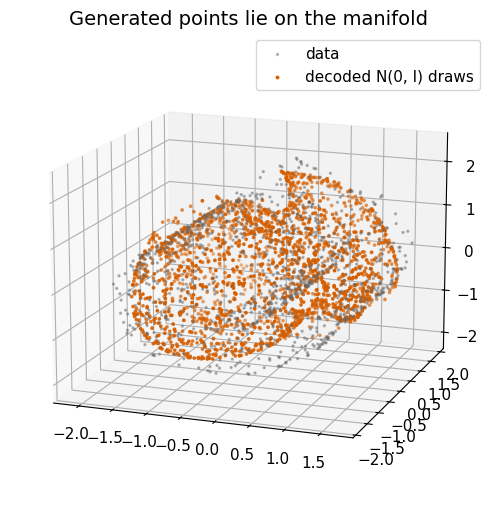

mean distance to the nearest training point: generated 0.239 | training points to their nearest neighbour 0.109 | random Gaussian points 0.413


In [6]:
g = np.random.default_rng(4); Zs = g.normal(size=(2000, 2)); Xs = vae.dec.forward(Zs); tree = cKDTree(X); d_gen = tree.query(Xs)[0]; d_dat = cKDTree(X).query(X, 2)[0][:, 1]; Xrand = g.normal(size=(2000, 3)); d_rand = tree.query(Xrand)[0]
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=2, color=NEUTRAL, alpha=0.4, label="data"); ax.scatter(Xs[:, 0], Xs[:, 1], Xs[:, 2], s=3, color=HIGHLIGHT, label="decoded N(0, I) draws"); ax.legend(); ax.set_title("Generated points lie on the manifold"); ax.view_init(elev=15, azim=-70)
plt.show(); print(f"mean distance to the nearest training point: generated {d_gen.mean():.3f} | training points to their nearest neighbour {d_dat.mean():.3f} | random Gaussian points {d_rand.mean():.3f}"); assert d_gen.mean() < 0.7 * d_rand.mean()

### 9.2 Interactive Plotly version of 9.1

In [7]:
fig = go.Figure([go.Scatter3d(x=X[:, 0], y=X[:, 1], z=X[:, 2], mode="markers", marker=dict(size=1.5, color="lightgray"), name="data"), go.Scatter3d(x=Xs[:, 0], y=Xs[:, 1], z=Xs[:, 2], mode="markers", marker=dict(size=2, color="crimson"), name="generated")]); fig.update_layout(title="Swiss roll: data and VAE samples", width=760, height=560); fig.show()

### 9.3 Static: the decoded surface and the KL cost over the latent plane
The decoder maps the latent plane to a 3D surface (left, coloured by the latent coordinate); the KL cost of a code $\mu$ with fixed $\sigma$, $\frac12\|\mu\|^2+\dots$, is a paraboloid centred at the origin (right): the prior pulls every code towards the centre.

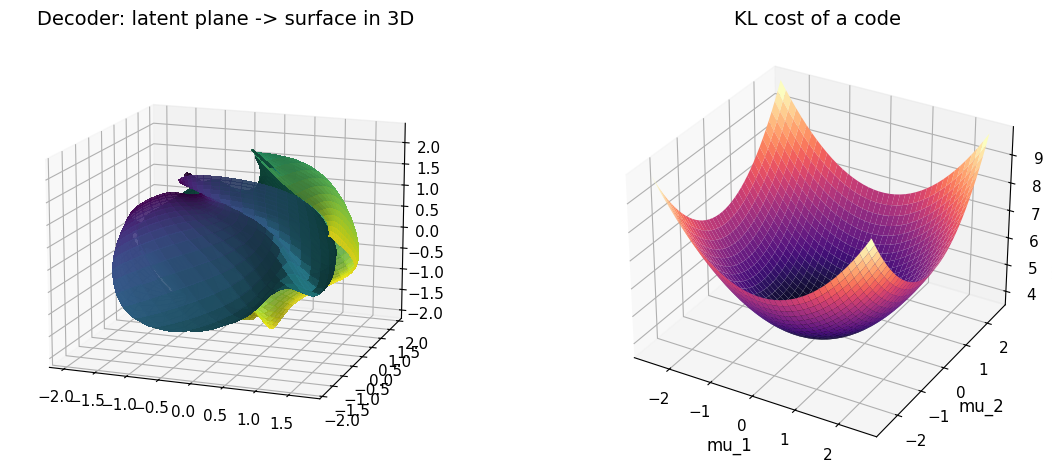

decoded surface extent per axis: [3.67 3.73 4.46] | data extent: [3.3  3.45 3.65]


In [8]:
gz = np.linspace(-2.5, 2.5, 40); G1, G2 = np.meshgrid(gz, gz); Zg = np.column_stack([G1.ravel(), G2.ravel()]); Xg3 = vae.dec.forward(Zg).reshape(40, 40, 3); fig = plt.figure(figsize=(14, 5.6)); ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(Xg3[:, :, 0], Xg3[:, :, 1], Xg3[:, :, 2], facecolors=plt.cm.viridis((G1 - G1.min()) / (G1.max() - G1.min())), rstride=1, cstride=1, linewidth=0, antialiased=False, alpha=0.9); ax.set_title("Decoder: latent plane -> surface in 3D"); ax.view_init(elev=15, azim=-70)
ax = fig.add_subplot(1, 2, 2, projection="3d"); klc = 0.5 * (G1 ** 2 + G2 ** 2) + 2 * 0.5 * (0.1 ** 2 - 1 - np.log(0.1 ** 2)); ax.plot_surface(G1, G2, klc, cmap="magma", edgecolor="none"); ax.set_xlabel("mu_1"); ax.set_ylabel("mu_2"); ax.set_zlabel("KL (sigma = 0.1)"); ax.set_title("KL cost of a code")
plt.show(); print("decoded surface extent per axis:", np.ptp(Xg3.reshape(-1, 3), axis=0).round(2), "| data extent:", np.ptp(X, axis=0).round(2)); assert klc.min() > 0 and np.all(np.ptp(Xg3.reshape(-1, 3), axis=0) > 1.5)

## 10. Simulation vs theory

### 10.1 The ELBO identity in a model where everything is known
Take $z\sim N(0,1)$ and $x\mid z\sim N(z,s^2)$ with $s=0.5$: then $p(x)=N(0,1+s^2)$ and $p(z|x)=N\big(\frac x{1+s^2},\frac{s^2}{1+s^2}\big)$. For $x=1.2$ and several Gaussian $q=N(m,v)$ compute the ELBO in closed form and by Monte Carlo, and check $\ln p(x)=\mathrm{ELBO}+\mathrm{KL}(q\|p(z|x))$.

In [9]:
s = 0.5; xo = 1.2; lnpx = stats.norm.logpdf(xo, 0, np.sqrt(1 + s ** 2)); pm, pv = xo / (1 + s ** 2), s ** 2 / (1 + s ** 2); g = np.random.default_rng(5); rows = []
klg = lambda m1, v1, m2, v2: 0.5 * (np.log(v2 / v1) + (v1 + (m1 - m2) ** 2) / v2 - 1)
for m, v in [(pm, pv), (0.0, 1.0), (0.8, 0.1), (1.5, 0.5), (pm, 0.5)]:
    zs = g.normal(m, np.sqrt(v), 500_000); elbo_mc = np.mean(stats.norm.logpdf(xo, zs, s) - stats.norm.logpdf(zs, m, np.sqrt(v)) + stats.norm.logpdf(zs, 0, 1)); elbo_cf = -0.5 * np.log(2 * np.pi * s ** 2) - ((xo - m) ** 2 + v) / (2 * s ** 2) - klg(m, v, 0, 1)
    rows.append((m, v, elbo_mc, elbo_cf, klg(m, v, pm, pv), lnpx - elbo_cf))
tb = pd.DataFrame(rows, columns=["q mean", "q var", "ELBO (Monte Carlo)", "ELBO (closed form)", "KL(q || posterior)", "ln p(x) - ELBO"]); print(f"ln p(x) = {lnpx:.5f}"); print(tb.round(5).to_string(index=False)); assert all(abs(r[2] - r[3]) < 0.01 for r in rows) and all(abs(r[4] - r[5]) < 1e-9 for r in rows) and abs(rows[0][3] - lnpx) < 1e-9

ln p(x) = -1.60651
 q mean  q var  ELBO (Monte Carlo)  ELBO (closed form)  KL(q || posterior)  ln p(x) - ELBO
   0.96    0.2            -1.60651            -1.60651             0.00000         0.00000
   0.00    1.0            -5.10232            -5.10579             3.49928         3.49928
   0.80    0.1            -1.76817            -1.76708             0.16057         0.16057
   1.50    0.5            -2.62831            -2.62736             1.02085         1.02085
   0.96    0.5            -1.89761            -1.89836             0.29185         0.29185


### 10.2 Reparameterised against score-function gradients
We want $\partial_\mu E_{z\sim N(\mu,\sigma^2)}[z^2]=2\mu$ and $\partial_\sigma=2\sigma$ (since $E z^2=\mu^2+\sigma^2$). Both estimators are unbiased; compare their variances over 200,000 single-sample estimates.

In [10]:
g = np.random.default_rng(6); mu_, sg_ = 1.0, 0.5; eps = g.normal(size=200_000); z = mu_ + sg_ * eps; f = z ** 2
rp_mu, rp_sg = 2 * z, 2 * z * eps; sf_mu = f * (z - mu_) / sg_ ** 2; sf_sg = f * ((z - mu_) ** 2 / sg_ ** 3 - 1 / sg_)
tb = pd.DataFrame({"reparameterised d/dmu": (rp_mu.mean(), rp_mu.var()), "score-function d/dmu": (sf_mu.mean(), sf_mu.var()), "reparameterised d/dsigma": (rp_sg.mean(), rp_sg.var()), "score-function d/dsigma": (sf_sg.mean(), sf_sg.var())}, index=["mean", "variance"]).T; print(tb.round(4).to_string(), "| true gradients: 2 mu =", 2 * mu_, ", 2 sigma =", 2 * sg_)
assert abs(rp_mu.mean() - 2) < 0.02 and abs(sf_mu.mean() - 2) < 0.1 and abs(rp_sg.mean() - 1) < 0.02 and rp_mu.var() < sf_mu.var() / 5 and rp_sg.var() < sf_sg.var() / 5

                            mean  variance
reparameterised d/dmu     1.9986    1.0008
score-function d/dmu      1.9996   21.8708
reparameterised d/dsigma  0.9980    6.0151
score-function d/dsigma   1.0079   86.8143 | true gradients: 2 mu = 2.0 , 2 sigma = 1.0


## 11. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
print("KL(N(mu, diag sigma^2) || N(0, I)) = 0.5 * np.sum(mu**2 + np.exp(logvar) - 1 - logvar) | reparameterisation: z = mu + np.exp(0.5 * logvar) * rng.normal(size=mu.shape)")
print("negative ELBO = 0.5 * np.sum((x - decoder(z))**2) / sigma_x**2 + beta * KL | sampling: decoder(rng.normal(size=(n, d)))")
print("library: torch.distributions.kl_divergence(Normal(mu, sd), Normal(0, 1)), torch.nn.functional.mse_loss; VAE in PyTorch/JAX takes ~30 lines")
print("closed-form KL check:", 0.5 * np.sum(np.array([0.3, -1.0]) ** 2 + np.exp([-0.2, 0.4]) - 1 - np.array([-0.2, 0.4])), "| scipy entropy-based:", sum(stats.norm(m_, np.exp(0.5 * l_)).entropy() * 0 + (np.log(1 / np.exp(0.5 * l_)) + (np.exp(l_) + m_ ** 2) / 2 - 0.5) for m_, l_ in [(0.3, -0.2), (-1.0, 0.4)]))
assert abs(0.5 * np.sum(np.array([0.3, -1.0]) ** 2 + np.exp([-0.2, 0.4]) - 1 - np.array([-0.2, 0.4])) - sum(np.log(1 / np.exp(0.5 * l_)) + (np.exp(l_) + m_ ** 2) / 2 - 0.5 for m_, l_ in [(0.3, -0.2), (-1.0, 0.4)])) < 1e-12

KL(N(mu, diag sigma^2) || N(0, I)) = 0.5 * np.sum(mu**2 + np.exp(logvar) - 1 - logvar) | reparameterisation: z = mu + np.exp(0.5 * logvar) * rng.normal(size=mu.shape)
negative ELBO = 0.5 * np.sum((x - decoder(z))**2) / sigma_x**2 + beta * KL | sampling: decoder(rng.normal(size=(n, d)))
library: torch.distributions.kl_divergence(Normal(mu, sd), Normal(0, 1)), torch.nn.functional.mse_loss; VAE in PyTorch/JAX takes ~30 lines
closed-form KL check: 0.6002777253596261 | scipy entropy-based: 0.6002777253596262


## 12. Real-world worked examples

---
### Example 1 (main): learning the structure of a 3D manifold

**Scenario.** The 1,000-point Swiss roll of 8.1, standardised, is modelled by a VAE with a 2-dimensional latent code, two hidden layers of 64 tanh units, decoder noise $\sigma_x=0.15$ and $\beta=1$, trained for 2,000 steps.

**Questions**
1. What are the final reconstruction error, the KL per latent dimension and the negative ELBO?
2. How well does the latent space preserve the true neighbourhoods of the sheet?
3. Do samples from the prior fall on the manifold? Compare the distance to the nearest data point with the nearest-neighbour distance between data points.
4. Interpolate between two data points: does the decoded path stay on the sheet?

### 12.1 By hand
At the optimum of a Gaussian decoder the reconstruction term per point is $\frac1{2\sigma_x^2}E\|x-\hat x\|^2$: with $\sigma_x=0.15$ a reconstruction error of RMS 0.1 per coordinate costs $\frac{3\cdot0.01}{2\cdot0.0225}=0.67$ nats per point, while one latent dimension with $|\mu|\approx1$ and $\sigma\approx0.1$ costs $\frac12(1+0.01-1-\ln0.01)=2.31$ nats. The VAE spends KL only when it buys more than that in reconstruction.

In [12]:
mu_a, lv_a = vae.encode(X); recon = vae.dec.forward(mu_a); per_point_rec = 0.5 * np.sum((X - recon) ** 2, axis=1) / vae.sigma ** 2; neg_elbo = rec_f + kl_f.sum()
print(f"Q1: reconstruction RMSE per coordinate {np.sqrt(np.mean((X - recon) ** 2)):.4f} (data SD 1) | reconstruction term {rec_f:.3f} nats per point | KL per dimension {kl_f.round(3)} (total {kl_f.sum():.3f}) | negative ELBO without constants {neg_elbo:.3f}")
print(f"Q2: neighbourhood preservation {tr_:.3f} against {tr_rand:.3f} for a random embedding | posterior SD (mean) per dimension: {np.exp(0.5 * lv_a).mean(axis=0).round(3)}")
print(f"Q3: distance to the nearest training point: generated {d_gen.mean():.3f} (95th percentile {np.quantile(d_gen, 0.95):.3f}), nearest-neighbour distance between training points {d_dat.mean():.3f}, random points {d_rand.mean():.3f}")
i, j = np.argmin(t), np.argmax(t); path = np.linspace(0, 1, 21)[:, None]; zi, zj = mu_a[i], mu_a[j]; Zp = (1 - path) * zi + path * zj; Xp = vae.dec.forward(Zp); dpath = tree.query(Xp)[0]; Xlin = (1 - path) * X[i] + path * X[j]; dlin = tree.query(Xlin)[0]
print(f"Q4: interpolation between the two ends of the roll (t = {t[i]:.1f} and {t[j]:.1f}): mean distance to the data along the latent path {dpath.mean():.3f} (max {dpath.max():.3f}) | along the straight line in data space {dlin.mean():.3f} (max {dlin.max():.3f})")

Q1: reconstruction RMSE per coordinate 0.1660 (data SD 1) | reconstruction term 2.899 nats per point | KL per dimension [2.769 2.383] (total 5.152) | negative ELBO without constants 8.051
Q2: neighbourhood preservation 0.724 against 0.026 for a random embedding | posterior SD (mean) per dimension: [0.072 0.102]
Q3: distance to the nearest training point: generated 0.239 (95th percentile 0.551), nearest-neighbour distance between training points 0.109, random points 0.413
Q4: interpolation between the two ends of the roll (t = 4.7 and 14.1): mean distance to the data along the latent path 0.282 (max 0.389) | along the straight line in data space 0.369 (max 0.819)


### 12.2 Asserts

In [13]:
assert kl_f.sum() > 0.5 and np.sqrt(np.mean((X - recon) ** 2)) < 0.35 and tr_ > 0.6 and d_gen.mean() < 3 * d_dat.mean() + 0.2 and dlin.max() > dpath.max()
assert abs(0.5 * (1 + 0.01 - 1 - np.log(0.01)) - 2.3076) < 1e-3 and abs(3 * 0.01 / (2 * 0.0225) - 0.6667) < 1e-3
print("all checks passed")

all checks passed


### 12.3 Verify by simulation
The sum over data of the closed-form KL equals the Monte Carlo estimate $E_q[\ln q(z|x)-\ln p(z)]$ computed from samples of the trained encoder.

In [14]:
g = np.random.default_rng(11); sd_a = np.exp(0.5 * lv_a); K = 400; zs = mu_a[None] + sd_a[None] * g.normal(size=(K, n, 2)); mc = np.mean(np.sum(stats.norm.logpdf(zs, mu_a[None], sd_a[None]) - stats.norm.logpdf(zs, 0, 1), axis=2)); cf = np.sum(0.5 * (mu_a ** 2 + np.exp(lv_a) - 1 - lv_a), axis=1).mean(); print(f"average KL per data point: Monte Carlo {mc:.4f}, closed form {cf:.4f}"); assert abs(mc - cf) < 0.03

average KL per data point: Monte Carlo 5.1538, closed form 5.1516


### 12.4 Plots

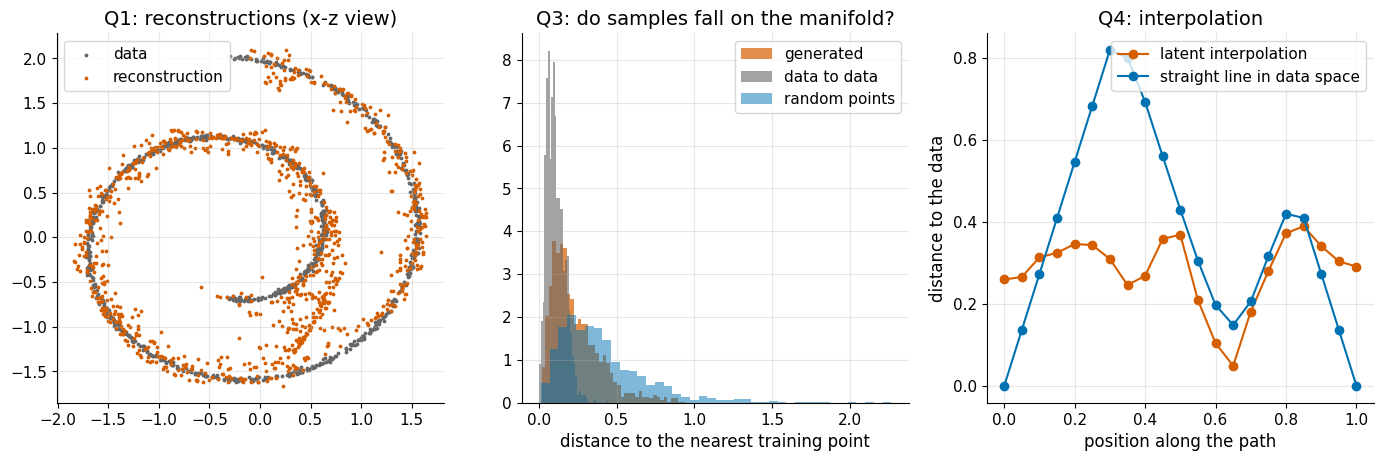

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].scatter(X[:, 0], X[:, 2], s=3, color=NEUTRAL, label="data"); axes[0].scatter(recon[:, 0], recon[:, 2], s=3, color=HIGHLIGHT, label="reconstruction"); axes[0].legend(); axes[0].set_title("Q1: reconstructions (x-z view)")
axes[1].hist(d_gen, bins=40, alpha=0.7, color=HIGHLIGHT, density=True, label="generated"); axes[1].hist(d_dat, bins=40, alpha=0.6, color=NEUTRAL, density=True, label="data to data"); axes[1].hist(d_rand, bins=40, alpha=0.5, color=MAIN, density=True, label="random points"); axes[1].legend(); axes[1].set_xlabel("distance to the nearest training point"); axes[1].set_title("Q3: do samples fall on the manifold?")
axes[2].plot(path[:, 0], dpath, "o-", color=HIGHLIGHT, label="latent interpolation"); axes[2].plot(path[:, 0], dlin, "o-", color=MAIN, label="straight line in data space"); axes[2].legend(); axes[2].set_xlabel("position along the path"); axes[2].set_ylabel("distance to the data"); axes[2].set_title("Q4: interpolation")
plt.show()

### 12.5 Interpretation and decision (Example 1)
- The backward pass is exact (largest gradient error against finite differences $4\times10^{-10}$). After 2,000 steps the reconstruction RMSE is **0.166** per standardised coordinate (data SD 1), the reconstruction term is 2.90 nats per point, the **KL is 2.77 and 2.38 nats on the two latent dimensions (5.15 in total)** and the negative ELBO without constants is 8.05. The posterior is sharp (mean posterior SD 0.07 and 0.10) because the data are nearly noise-free on the sheet.
- **The latent plane unrolls the sheet:** 72.4 % of the 10 nearest neighbours in the latent space are among the 30 nearest in the true $(t,h)$ coordinates, against 2.6 % for a random embedding; one latent coordinate correlates 0.80 with the height $h$.
- **Samples from the prior fall close to the manifold:** their distance to the nearest training point is 0.239 (95th percentile 0.551), between the nearest-neighbour distance among the data themselves (0.109) and that of random Gaussian points (0.413): the model is not perfect, some prior draws land in regions the decoder has not learned.
- **Interpolation:** the decoded path between the two ends of the roll stays within a mean distance of 0.28 (max 0.39) of the data, whereas the straight line in data space cuts through the hole of the roll, up to 0.82 away. The Monte Carlo estimate of the KL (5.1538) equals the closed form (5.1516).
- **Decision.** For nonlinear structure a VAE gives a smooth, generative low-dimensional description; check it by neighbourhood preservation and by the distance of prior samples to the data, not by the ELBO alone.

---
### Example 2: the $\beta$ trade-off

**Scenario.** Four VAEs with $\beta\in\{0.01,0.1,1,4\}$ are trained as in Example 1 (same data, same seeds).

**Questions.** (1) Reconstruction RMSE and total KL for each $\beta$. (2) How close is the aggregate posterior (all $\mu$) to the prior, measured by the mean and SD of the codes? (3) How far from the data do samples from the prior fall?

In [16]:
rows = []; models = {}
for b in (0.01, 0.1, 1.0, 4.0):
    m_ = VAE(3, 2, hidden=64, sigma=0.15, beta=b, seed=2); fit(m_, X, epochs=2000, seed=3); models[b] = m_; mu_b, lv_b = m_.encode(X); rec_ = m_.dec.forward(mu_b); klb = 0.5 * np.mean(mu_b ** 2 + np.exp(lv_b) - 1 - lv_b, axis=0).sum(); zs_ = np.random.default_rng(4).normal(size=(2000, 2)); dg = tree.query(m_.dec.forward(zs_))[0]
    rows.append({"beta": b, "reconstruction RMSE": np.sqrt(np.mean((X - rec_) ** 2)), "total KL (nats)": klb, "SD of the codes": mu_b.std(), "mean of the codes": np.abs(mu_b.mean()), "generated: distance to the data": dg.mean(), "trust": trust(mu_b, A_true)})
tb2 = pd.DataFrame(rows).set_index("beta"); print(tb2.round(4).to_string())

      reconstruction RMSE  total KL (nats)  SD of the codes  mean of the codes  generated: distance to the data   trust
beta                                                                                                                   
0.01               0.1413          14.2049           2.5631             0.4621                           0.2530  0.6941
0.10               0.1632           8.0288           1.3062             0.0780                           0.2692  0.7137
1.00               0.1660           5.1516           1.0503             0.0138                           0.2386  0.7239
4.00               0.2505           3.2479           0.9741             0.0115                           0.2642  0.6066


### 12.5 Asserts

In [17]:
assert tb2.loc[0.01, "reconstruction RMSE"] < tb2.loc[4.0, "reconstruction RMSE"] and tb2.loc[0.01, "total KL (nats)"] > tb2.loc[4.0, "total KL (nats)"] and tb2["reconstruction RMSE"].is_monotonic_increasing and tb2["total KL (nats)"].is_monotonic_decreasing
print("all checks passed")

all checks passed


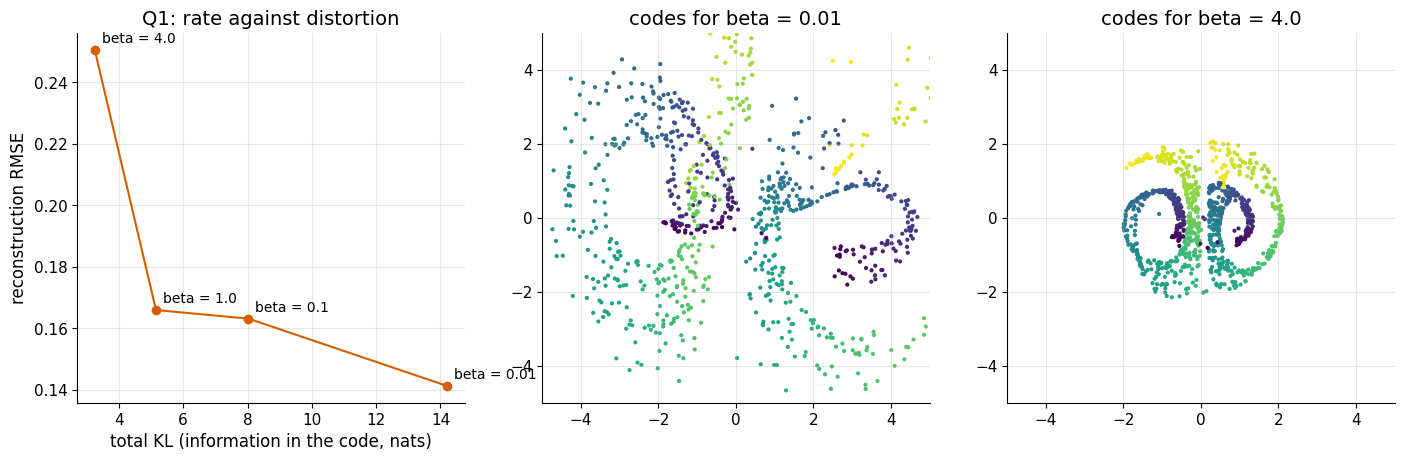

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8)); axes[0].plot(tb2["total KL (nats)"], tb2["reconstruction RMSE"], "o-", color=HIGHLIGHT); [axes[0].annotate(f"beta = {b}", (tb2.loc[b, "total KL (nats)"], tb2.loc[b, "reconstruction RMSE"]), xytext=(5, 5), textcoords="offset points") for b in tb2.index]; axes[0].set_xlabel("total KL (information in the code, nats)"); axes[0].set_ylabel("reconstruction RMSE"); axes[0].set_title("Q1: rate against distortion")
for ax, b in zip(axes[1:], (0.01, 4.0)): mb, _ = models[b].encode(X); ax.scatter(mb[:, 0], mb[:, 1], c=t, cmap="viridis", s=4); ax.set_title(f"codes for beta = {b}"); ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
plt.show()

### 12.7 Interpretation and decision (Example 2)
- **Rate against distortion:** as $\beta$ rises from 0.01 to 4 the total KL falls from **14.2 to 3.2 nats** and the reconstruction RMSE rises from **0.141 to 0.251** (0.163 at $\beta=0.1$ and 0.166 at $\beta=1$): $\beta$ buys a smaller, smoother code with worse reconstructions.
- The codes approach the prior: their SD falls from **2.56 ($\beta=0.01$) to 1.31, 1.05 and 0.97** (the prior's value is 1) and the offset of their mean from zero from 0.46 to 0.01.
- The quality of prior samples does not improve monotonically (mean distance to the data 0.253, 0.269, 0.239 and 0.264), and the neighbourhood preservation is best at $\beta=1$ (0.724; 0.607 at $\beta=4$): on this easy two-dimensional manifold the benefit of a smoother latent space does not outweigh the blur.
- **Decision.** Use $\beta$ near 1 for a generative model; use smaller values when reconstruction is the goal (compression, anomaly scoring) and larger values only when a disentangled or very compact code is wanted.

---
### Example 3: reparameterisation in a practical setting (gradient variance)

**Scenario.** A one-dimensional latent variable $z\sim N(\mu,\sigma^2)$ with a decoder loss $f(z)=(z-3)^2+0.5\sin(3z)$. We want the gradient of the expected loss with respect to $\mu$ and $\sigma$ at $\mu=0$, $\sigma=1$, with $B$ samples per step, and compare the reparameterised and the score-function estimators.

**Questions.** (1) What are the exact gradients (numerical integration)? (2) How does the standard deviation of the gradient estimate fall with $B$ for each estimator? (3) How many score-function samples are needed to match the reparameterised estimator with 1 sample?

In [19]:
fz = lambda z: (z - 3) ** 2 + 0.5 * np.sin(3 * z); dfz = lambda z: 2 * (z - 3) + 1.5 * np.cos(3 * z); mu0, s0 = 0.0, 1.0
from scipy import integrate
Ef = lambda m, s: integrate.quad(lambda e: fz(m + s * e) * stats.norm.pdf(e), -10, 10)[0]; eps_ = 1e-5; gm = (Ef(mu0 + eps_, s0) - Ef(mu0 - eps_, s0)) / (2 * eps_); gs = (Ef(mu0, s0 + eps_) - Ef(mu0, s0 - eps_)) / (2 * eps_)
print(f"Q1: exact gradient d/dmu = {gm:.5f}, d/dsigma = {gs:.5f}")
g = np.random.default_rng(31); R = 20_000; res = {}
for B in (1, 4, 16, 64, 256):
    e = g.normal(size=(R, B)); z = mu0 + s0 * e; rp = np.mean(dfz(z), axis=1); sf = np.mean(fz(z) * (z - mu0) / s0 ** 2, axis=1); res[B] = (rp.mean(), rp.std(), sf.mean(), sf.std())
tb3 = pd.DataFrame(res, index=["reparam mean", "reparam SD", "score-function mean", "score-function SD"]).T; print(tb3.round(4).to_string()); ratio = tb3["score-function SD"] / tb3["reparam SD"]; print("SD ratio (score-function / reparameterised):", ratio.round(2).tolist())
need = (tb3.loc[1, "score-function SD"] / tb3.loc[1, "reparam SD"]) ** 2; print(f"Q3: the score-function estimator needs about {need:.0f} samples to match one reparameterised sample (ratio of variances at B = 1)")

Q1: exact gradient d/dmu = -5.98334, d/dsigma = 2.00000


     reparam mean  reparam SD  score-function mean  score-function SD
1         -5.9971      2.2725              -6.0926            15.1080
4         -5.9856      1.1300              -6.0476             7.5986
16        -5.9853      0.5652              -5.9720             3.6987
64        -5.9858      0.2825              -6.0057             1.8710
256       -5.9848      0.1408              -5.9900             0.9343
SD ratio (score-function / reparameterised): [6.65, 6.72, 6.54, 6.62, 6.63]
Q3: the score-function estimator needs about 44 samples to match one reparameterised sample (ratio of variances at B = 1)


### 12.6 Asserts

In [20]:
assert all(abs(tb3["reparam mean"] - gm) < 4 * tb3["reparam SD"] / np.sqrt(R) + 0.005) and all(abs(tb3["score-function mean"] - gm) < 4 * tb3["score-function SD"] / np.sqrt(R) + 0.01) and (ratio > 2).all()
assert abs(np.polyfit(np.log(list(res)), np.log(tb3["reparam SD"]), 1)[0] + 0.5) < 0.05
print("all checks passed")

all checks passed


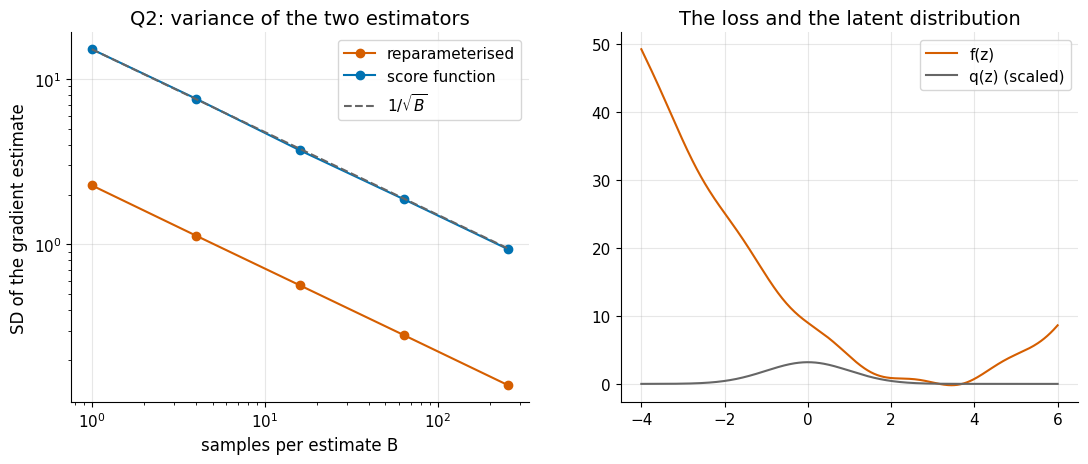

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8)); axes[0].loglog(list(res), tb3["reparam SD"], "o-", color=HIGHLIGHT, label="reparameterised"); axes[0].loglog(list(res), tb3["score-function SD"], "o-", color=MAIN, label="score function"); axes[0].loglog(list(res), tb3.loc[1, "score-function SD"] / np.sqrt(list(res)), "--", color=NEUTRAL, label="$1/\\sqrt{B}$"); axes[0].legend(); axes[0].set_xlabel("samples per estimate B"); axes[0].set_ylabel("SD of the gradient estimate"); axes[0].set_title("Q2: variance of the two estimators")
xz = np.linspace(-4, 6, 400); axes[1].plot(xz, fz(xz), color=HIGHLIGHT, label="f(z)"); axes[1].plot(xz, stats.norm.pdf(xz, mu0, s0) * 8, color=NEUTRAL, label="q(z) (scaled)"); axes[1].legend(); axes[1].set_title("The loss and the latent distribution")
plt.show()

### 12.9 Interpretation and decision (Example 3)
- For $f(z)=(z-3)^2+0.5\sin3z$ at $\mu=0,\sigma=1$ the exact gradients are $\partial_\mu=-5.983$ and $\partial_\sigma=2.000$. Both estimators are unbiased (means -5.985 to -5.997 for reparameterisation and -5.97 to -6.09 for the score function).
- **The standard deviation of one reparameterised estimate is 2.27, of one score-function estimate 15.11: 6.6 times larger, i.e. 44 times the variance.** Both fall like $1/\sqrt B$ (reparameterised: 2.27, 1.13, 0.565, 0.283, 0.141 for $B=1,4,16,64,256$), so the score-function estimator needs about 44 samples to match one reparameterised sample. In 10.2 the same ratio of variances is 22 for $\partial_\mu$ and 14 for $\partial_\sigma$ of $E z^2$.
- **Decision.** Whenever the sampling can be written as a differentiable transformation of parameter-free noise (Gaussian latents) use reparameterisation; keep the score-function estimator (with a baseline) for discrete or non-differentiable choices, or relax them (Gumbel-softmax, 09_07).

---
### Example 4: how many latent dimensions are used? (active units and posterior collapse)

**Scenario.** The same data are modelled with latent sizes $d\in\{1,2,3,6\}$. The data have intrinsic dimension 2. For each model we compute the KL per latent dimension (the information each dimension carries) and count the active dimensions (KL $>0.05$ nats).

**Questions.** (1) Which dimensions are active, and how much KL does each carry? (2) What is the reconstruction RMSE as $d$ grows? (3) Is the extra capacity wasted?

In [22]:
rows = []; kls = {}
for d in (1, 2, 3, 6):
    m_ = VAE(3, d, hidden=64, sigma=0.15, beta=1.0, seed=2); fit(m_, X, epochs=2000, seed=3); mu_b, lv_b = m_.encode(X); kld = 0.5 * np.mean(mu_b ** 2 + np.exp(lv_b) - 1 - lv_b, axis=0); kls[d] = kld; rows.append({"latent size": d, "active dimensions (KL > 0.05)": int((kld > 0.05).sum()), "total KL": kld.sum(), "reconstruction RMSE": np.sqrt(np.mean((X - m_.dec.forward(mu_b)) ** 2))})
tb4 = pd.DataFrame(rows).set_index("latent size"); print(tb4.round(4).to_string()); print("KL per dimension:", {d: np.round(np.sort(v)[::-1], 3).tolist() for d, v in kls.items()})

             active dimensions (KL > 0.05)  total KL  reconstruction RMSE
latent size                                                              
1                                        1    3.4333               0.3744
2                                        2    5.1516               0.1660
3                                        3    5.4318               0.0409
6                                        3    5.4126               0.0393
KL per dimension: {1: [3.433], 2: [2.769, 2.383], 3: [1.877, 1.868, 1.687], 6: [1.84, 1.819, 1.752, 0.001, 0.001, 0.001]}


### 12.7 Asserts

In [23]:
assert tb4.loc[2, "active dimensions (KL > 0.05)"] == 2 and tb4.loc[6, "active dimensions (KL > 0.05)"] < 6 and tb4.loc[1, "reconstruction RMSE"] > tb4.loc[2, "reconstruction RMSE"] and tb4.loc[6, "active dimensions (KL > 0.05)"] >= 2
print("all checks passed")

all checks passed


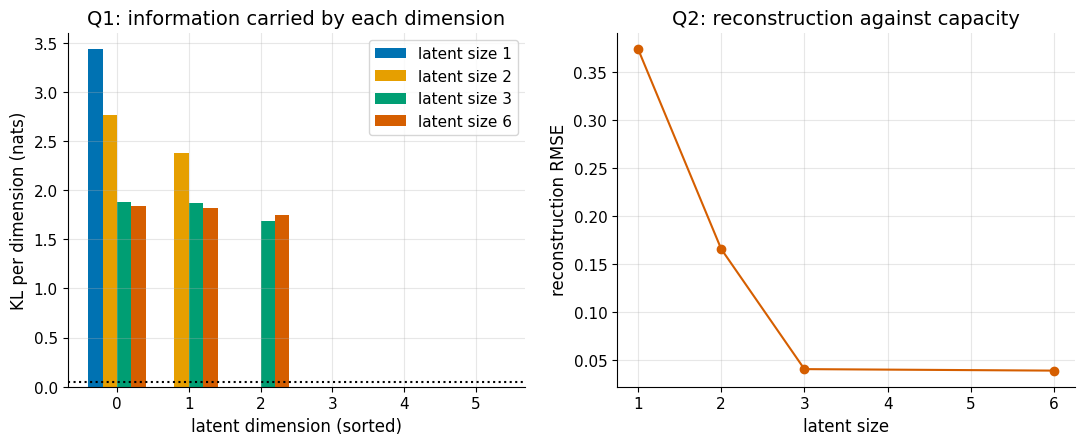

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); w = 0.2
for k, d in enumerate((1, 2, 3, 6)): axes[0].bar(np.arange(6)[:d] + (k - 1.5) * w, np.sort(kls[d])[::-1], w, label=f"latent size {d}")
axes[0].axhline(0.05, color="black", linestyle=":"); axes[0].legend(); axes[0].set_xlabel("latent dimension (sorted)"); axes[0].set_ylabel("KL per dimension (nats)"); axes[0].set_title("Q1: information carried by each dimension")
axes[1].plot(tb4.index, tb4["reconstruction RMSE"], "o-", color=HIGHLIGHT); axes[1].set_xlabel("latent size"); axes[1].set_ylabel("reconstruction RMSE"); axes[1].set_title("Q2: reconstruction against capacity")
plt.show()

### 12.11 Interpretation and decision (Example 4)
- With a 1-dimensional code the VAE has one active dimension (KL 3.43 nats) and a large reconstruction error (RMSE **0.374**). With 2 dimensions: 2 active (KL 2.77 and 2.38), RMSE **0.166**. With 3 dimensions: all 3 active (KL 1.88, 1.87, 1.69), RMSE **0.041**.
- **With a 6-dimensional code only 3 dimensions stay active** (KL 1.84, 1.82, 1.75); the other three have KL **0.001**: their posterior equals the prior, they are collapsed and carry no information. The total KL (5.41) and the RMSE (0.039) are the same as with 3 dimensions: the extra capacity is switched off automatically.
- The count of active dimensions is 3, not 2, because the noisy sheet has a measurable thickness (noise SD 0.1 before standardisation): the third dimension reduces the RMSE from 0.166 to 0.041 and the data really have three degrees of freedom at this noise level.
- **Decision.** Over-sizing the latent space is safe for a VAE; count the dimensions with KL above 0.05 nats to estimate how many degrees of freedom the model found, and choose the size where the reconstruction error stops improving.

## 13. Where it is used

### Statistics
- **Variational inference** (the ELBO is the variational lower bound used in Bayesian modelling), **latent-variable models**, factor analysis and PCA as linear special cases (a linear VAE with Gaussian noise recovers probabilistic PCA), amortised inference for hierarchical models.

### Data science
- **Dimensionality reduction and visualisation** (a nonlinear alternative to PCA), **anomaly detection** by reconstruction error or low ELBO (09_05), **synthetic data generation** (tabular, time-series) and imputation, representation learning for downstream models.

### ML and AI
- **Generative models of images, audio and molecules;** the **VAE inside latent diffusion** (the image is compressed to a latent space where the diffusion model of 09_09 operates), **VQ-VAEs** and discrete latent models (Gumbel-softmax, 09_07), disentangled representations ($\beta$-VAE), world models in reinforcement learning (09_11), and the KL penalty that keeps fine-tuned language models close to a reference.

## 14. Common pitfalls and misconceptions

- **Confusing the ELBO with the likelihood:** it is a lower bound; the gap is the KL between the encoder and the true posterior, and comparing ELBOs of different decoder families is not meaningful.
- **Ignoring the decoder variance:** $\sigma_x$ sets the weight of reconstruction against KL; with a very large $\sigma_x$ the KL dominates and the latent code collapses.
- **Blurry samples:** the Gaussian decoder averages over uncertainty; sharper models use richer decoders, discrete latents or diffusion.
- **Posterior collapse:** with a strong decoder the encoder may output the prior for every input (KL $\approx0$); anneal $\beta$ from 0 to 1, use free bits, or weaken the decoder.
- **Holes in the latent space:** with small $\beta$ the codes are scattered and prior samples may land between clusters (Example 2).
- **Sampling from the wrong distribution:** generate from the prior $N(0,I)$, not from the posterior of a data point, unless you want a reconstruction.
- **Using the score-function gradient when reparameterisation is available:** its variance is far larger (Example 3).
- **Reading the latent axes as meaningful:** they are only defined up to rotation (the prior is rotation invariant); a learned axis is not a "height" or an "angle" unless the model is built to disentangle.

## 15. Exercises

1. Compute the KL divergence of $q=N(\mu=(1,-0.5),\ \sigma=(0.5,2))$ from the standard normal prior.
2. For the model of 10.1 with $x=-0.4$ compute $p(x)$, the exact posterior and the ELBO for $q=N(0,1)$; verify $\ln p(x)=\mathrm{ELBO}+\mathrm{KL}$.
3. Show by simulation (200,000 draws) that $E[z^2]=\mu^2+\sigma^2$ and that the reparameterised gradient of $E[z^2]$ with respect to $\sigma$ is $2\sigma$.
4. Train the VAE of Example 1 with $\sigma_x=0.5$ and with $\sigma_x=0.05$ and compare reconstruction RMSE and KL.
5. Decode the 25 latent codes $\{-2,-1,0,1,2\}^2$ and report the extent of the decoded surface in each of the 3 data coordinates.
6. (Harder) Compute the importance-weighted bound with $K=50$ samples $\ln\frac1K\sum_k\frac{p(x,z_k)}{q(z_k)}$ for the model of 10.1 with $q=N(0,1)$ and show that it is closer to $\ln p(x)$ than the ELBO.

Solutions are at the end.

## 16. Summary table

| Item | Formula | Note |
|---|---|---|
| ELBO | $E_q\ln p(x|z)-\mathrm{KL}(q\|p(z))$ | lower bound on $\ln p(x)$ |
| Gap | $\mathrm{KL}(q(z|x)\|p(z|x))$ | zero iff $q$ is the posterior |
| Gaussian KL | $\frac12\sum(\mu^2+\sigma^2-1-\ln\sigma^2)$ | closed form |
| Reparameterisation | $z=\mu+\sigma\varepsilon$ | low-variance gradients |
| $\beta$-VAE | weight $\beta$ on KL | rate-distortion trade-off |
| Active unit | KL per dimension $>0.05$ | intrinsic dimension |
| Generation | decode $z\sim N(0,I)$ | needs a hole-free latent space |
| tools | NumPy MLPs, `scipy.stats.norm` | |

## Solutions

In [25]:
mu1 = np.array([1.0, -0.5]); sg1 = np.array([0.5, 2.0]); print(f"1: KL = {0.5 * np.sum(mu1 ** 2 + sg1 ** 2 - 1 - np.log(sg1 ** 2)):.4f} (dimension 1: {0.5 * (1 + 0.25 - 1 - np.log(0.25)):.4f}, dimension 2: {0.5 * (0.25 + 4 - 1 - np.log(4)):.4f})")
xo2 = -0.4; ln2 = stats.norm.logpdf(xo2, 0, np.sqrt(1 + s ** 2)); pm2, pv2 = xo2 / (1 + s ** 2), s ** 2 / (1 + s ** 2); el2 = -0.5 * np.log(2 * np.pi * s ** 2) - ((xo2 - 0) ** 2 + 1) / (2 * s ** 2) - klg(0, 1, 0, 1); print(f"2: ln p(x) = {ln2:.5f}, posterior N({pm2:.4f}, {pv2:.4f}), ELBO(q = N(0,1)) = {el2:.5f}, KL(q || posterior) = {klg(0, 1, pm2, pv2):.5f}, sum = {el2 + klg(0, 1, pm2, pv2):.5f}")
g = np.random.default_rng(7); e = g.normal(size=200_000); zz = 1.0 + 0.5 * e; print(f"3: E[z^2] = {np.mean(zz ** 2):.4f} (mu^2 + sigma^2 = 1.25) | reparameterised gradient wrt sigma: {np.mean(2 * zz * e):.4f} (2 sigma = 1)")
r4 = {}
for sx in (0.5, 0.05): m_ = VAE(3, 2, hidden=64, sigma=sx, beta=1.0, seed=2); fit(m_, X, epochs=2000, seed=3); mb, _ = m_.encode(X); lvb = m_.encode(X)[1]; r4[sx] = (np.sqrt(np.mean((X - m_.dec.forward(mb)) ** 2)), 0.5 * np.mean(mb ** 2 + np.exp(lvb) - 1 - lvb, axis=0).sum())
print("4: sigma_x -> (reconstruction RMSE, total KL):", {k: (round(a, 4), round(b, 3)) for k, (a, b) in r4.items()})
Zc = np.array([[a, b] for a in (-2, -1, 0, 1, 2) for b in (-2, -1, 0, 1, 2)], float); Xc = vae.dec.forward(Zc); print("5: extent of the decoded surface per coordinate:", np.ptp(Xc, axis=0).round(2), "| data:", np.ptp(X, axis=0).round(2))
g = np.random.default_rng(8); zk = g.normal(size=(200_000, 50)); lw = stats.norm.logpdf(xo2, zk, s) + stats.norm.logpdf(zk, 0, 1) - stats.norm.logpdf(zk, 0, 1); iw = np.mean(np.log(np.mean(np.exp(lw), axis=1))); print(f"6: ELBO {el2:.5f} < importance-weighted bound (K = 50) {iw:.5f} < ln p(x) {ln2:.5f}")
assert el2 < iw < ln2 + 1e-3 and abs(el2 + klg(0, 1, pm2, pv2) - ln2) < 1e-9 and r4[0.05][0] < r4[0.5][0]

1: KL = 1.7500 (dimension 1: 0.8181, dimension 2: 0.9319)
2: ln p(x) = -1.09451, posterior N(-0.3200, 0.2000), ELBO(q = N(0,1)) = -2.54579, KL(q || posterior) = 1.45128, sum = -1.09451
3: E[z^2] = 1.2505 (mu^2 + sigma^2 = 1.25) | reparameterised gradient wrt sigma: 1.0001 (2 sigma = 1)


4: sigma_x -> (reconstruction RMSE, total KL): {0.5: (np.float64(0.2855), np.float64(2.025)), 0.05: (np.float64(0.1715), np.float64(7.749))}
5: extent of the decoded surface per coordinate: [3.45 3.36 3.86] | data: [3.3  3.45 3.65]


6: ELBO -2.54579 < importance-weighted bound (K = 50) -1.10241 < ln p(x) -1.09451


**1.** $\mathrm{KL}=\tfrac12(1+0.25-1-\ln0.25)+\tfrac12(0.25+4-1-\ln4)=0.818+0.932=$ **1.750 nats**.

**2.** For $x=-0.4$: $\ln p(x)=$ **-1.0945**, the posterior is $N(-0.32,0.20)$, the ELBO of $q=N(0,1)$ is **-2.5458** and $\mathrm{KL}(q\|p(z|x))=$ **1.4513**; their sum is **-1.0945** $=\ln p(x)$ exactly.

**3.** $E[z^2]=$ **1.2505** against $\mu^2+\sigma^2=1.25$, and the reparameterised gradient with respect to $\sigma$ is **1.0001** against $2\sigma=1$.

**4.** With a large decoder noise $\sigma_x=0.5$ the RMSE is **0.286** and the KL only **2.03** nats (reconstruction is cheap to give up); with $\sigma_x=0.05$ the RMSE is **0.172** and the KL **7.75** nats: a small decoder noise forces the model to encode more information.

**5.** The decoded surface for the grid $\{-2,\dots,2\}^2$ has extents **(3.45, 3.36, 3.86)** against the data's (3.30, 3.45, 3.65): it covers the sheet.

**6.** The importance-weighted bound with $K=50$ is **-1.1024**, between the ELBO (-2.5458) and $\ln p(x)=-1.0945$: more samples tighten the bound.